In [137]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv('/content/household_power_consumption.txt',sep=';')
df

/tmp/ipykernel_701/3762830471.py:3: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('/content/household_power_consumption.txt',sep=';')


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0
...,...,...,...,...,...,...,...,...,...
2075254,26/11/2010,20:58:00,0.946,0.0,240.43,4.0,0.0,0.0,0.0
2075255,26/11/2010,20:59:00,0.944,0.0,240.0,4.0,0.0,0.0,0.0
2075256,26/11/2010,21:00:00,0.938,0.0,239.82,3.8,0.0,0.0,0.0
2075257,26/11/2010,21:01:00,0.934,0.0,239.7,3.8,0.0,0.0,0.0


In [138]:
#DATA UNDERSTANDING

#first 3 rows
print(df.head(3))

         Date      Time Global_active_power Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00               4.216                 0.418  234.840   
1  16/12/2006  17:25:00               5.360                 0.436  233.630   
2  16/12/2006  17:26:00               5.374                 0.498  233.290   

  Global_intensity Sub_metering_1 Sub_metering_2  Sub_metering_3  
0           18.400          0.000          1.000            17.0  
1           23.000          0.000          1.000            16.0  
2           23.000          0.000          2.000            17.0  


In [139]:
#last 3 rows
print(df.tail(3))

               Date      Time Global_active_power Global_reactive_power  \
2075256  26/11/2010  21:00:00               0.938                   0.0   
2075257  26/11/2010  21:01:00               0.934                   0.0   
2075258  26/11/2010  21:02:00               0.932                   0.0   

        Voltage Global_intensity Sub_metering_1 Sub_metering_2  Sub_metering_3  
2075256  239.82              3.8            0.0            0.0             0.0  
2075257   239.7              3.8            0.0            0.0             0.0  
2075258  239.55              3.8            0.0            0.0             0.0  


In [140]:
#number of rows and column
print(df.shape)
#dimension
print(df.ndim)

(2075259, 9)
2


In [141]:
#statistical summary
print(df.describe())

       Sub_metering_3
count    2.049280e+06
mean     6.458447e+00
std      8.437154e+00
min      0.000000e+00
25%      0.000000e+00
50%      1.000000e+00
75%      1.700000e+01
max      3.100000e+01


In [142]:
#information
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    object 
 3   Global_reactive_power  object 
 4   Voltage                object 
 5   Global_intensity       object 
 6   Sub_metering_1         object 
 7   Sub_metering_2         object 
 8   Sub_metering_3         float64
dtypes: float64(1), object(8)
memory usage: 142.5+ MB
None


In [143]:
#datatypes
print(df.dtypes)

Date                      object
Time                      object
Global_active_power       object
Global_reactive_power     object
Voltage                   object
Global_intensity          object
Sub_metering_1            object
Sub_metering_2            object
Sub_metering_3           float64
dtype: object


In [144]:
#number of unique values of each column
print(df.nunique())

Date                     1442
Time                     1440
Global_active_power      6534
Global_reactive_power     896
Voltage                  5168
Global_intensity          377
Sub_metering_1            153
Sub_metering_2            145
Sub_metering_3             32
dtype: int64


In [145]:
#column names
print(df.columns)
#non-numerical column
print(df.select_dtypes(include=object).columns)
#numerical column
print(df.select_dtypes(exclude=object).columns)

Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='object')
Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2'],
      dtype='object')
Index(['Sub_metering_3'], dtype='object')


In [146]:
#duplicate values
print(df.duplicated().sum())

0


In [147]:
#null value
print(df.isnull().sum())

Date                         0
Time                         0
Global_active_power          0
Global_reactive_power        0
Voltage                      0
Global_intensity             0
Sub_metering_1               0
Sub_metering_2               0
Sub_metering_3           25979
dtype: int64


In [148]:
#DATA CLEANING

#extracting hours from time column
df['Time'] = pd.to_datetime(df['Time'], format='%H:%M:%S')
df['Hour'] = df['Time'].dt.hour
df=df.drop('Time',axis=1)

In [149]:
#extracting year and month from date column
df['Date']=pd.to_datetime(df['Date'],format="mixed")
df['Month']=df['Date'].dt.month
df['Year']=df['Date'].dt.year
df=df.drop('Date',axis=1)
df

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Month,Year
0,4.216,0.418,234.840,18.400,0.000,1.000,17.0,17,12,2006
1,5.360,0.436,233.630,23.000,0.000,1.000,16.0,17,12,2006
2,5.374,0.498,233.290,23.000,0.000,2.000,17.0,17,12,2006
3,5.388,0.502,233.740,23.000,0.000,1.000,17.0,17,12,2006
4,3.666,0.528,235.680,15.800,0.000,1.000,17.0,17,12,2006
...,...,...,...,...,...,...,...,...,...,...
2075254,0.946,0.0,240.43,4.0,0.0,0.0,0.0,20,11,2010
2075255,0.944,0.0,240.0,4.0,0.0,0.0,0.0,20,11,2010
2075256,0.938,0.0,239.82,3.8,0.0,0.0,0.0,21,11,2010
2075257,0.934,0.0,239.7,3.8,0.0,0.0,0.0,21,11,2010


In [150]:
#converting unusual values(?) to nan
cols = ['Global_active_power', 'Global_reactive_power',
        'Voltage', 'Global_intensity',
        'Sub_metering_1', 'Sub_metering_2']
for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [151]:
#null values
print(df.isnull().sum())
col=df.select_dtypes(exclude=object).columns
for i in col:
    df[i]=df[i].fillna(df[i].median())
print(df.isnull().sum())

Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
Hour                         0
Month                        0
Year                         0
dtype: int64
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
Hour                     0
Month                    0
Year                     0
dtype: int64


In [152]:
#datatypes
print(df.dtypes)

Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
Hour                       int32
Month                      int32
Year                       int32
dtype: object


In [153]:
#input selection
x=df
x

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Month,Year
0,4.216,0.418,234.84,18.4,0.0,1.0,17.0,17,12,2006
1,5.360,0.436,233.63,23.0,0.0,1.0,16.0,17,12,2006
2,5.374,0.498,233.29,23.0,0.0,2.0,17.0,17,12,2006
3,5.388,0.502,233.74,23.0,0.0,1.0,17.0,17,12,2006
4,3.666,0.528,235.68,15.8,0.0,1.0,17.0,17,12,2006
...,...,...,...,...,...,...,...,...,...,...
2075254,0.946,0.000,240.43,4.0,0.0,0.0,0.0,20,11,2010
2075255,0.944,0.000,240.00,4.0,0.0,0.0,0.0,20,11,2010
2075256,0.938,0.000,239.82,3.8,0.0,0.0,0.0,21,11,2010
2075257,0.934,0.000,239.70,3.8,0.0,0.0,0.0,21,11,2010


In [154]:
#feature Scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
x_scaled

array([[ 2.97559138,  2.62913874, -1.86414634, ...,  0.79443245,
         1.60070395, -2.1588099 ],
       [ 4.06297714,  2.78978819, -2.239958  , ...,  0.79443245,
         1.60070395, -2.1588099 ],
       [ 4.07628431,  3.34313627, -2.34555798, ...,  0.79443245,
         1.60070395, -2.1588099 ],
       ...,
       [-0.14018705, -1.10149834, -0.31741733, ...,  1.37228132,
         1.30987017,  1.3851639 ],
       [-0.1439891 , -1.10149834, -0.35468791, ...,  1.37228132,
         1.30987017,  1.3851639 ],
       [-0.14589012, -1.10149834, -0.40127613, ...,  1.37228132,
         1.30987017,  1.3851639 ]])

In [155]:
#finding inertia for each corresponding K
from sklearn.cluster import KMeans
wcss=[]
for i in range(1,11):
  kmeans=KMeans(n_clusters=i,init="k-means++",random_state=41)
  kmeans.fit(x_scaled)
  wcss.append(kmeans.inertia_)
wcss

[20752589.99999825,
 16149213.8255858,
 15045141.723008191,
 14217261.845479866,
 11660590.818973938,
 9955530.75814921,
 9318687.728566933,
 8847804.820810745,
 8530882.488940284,
 8041668.941292897]

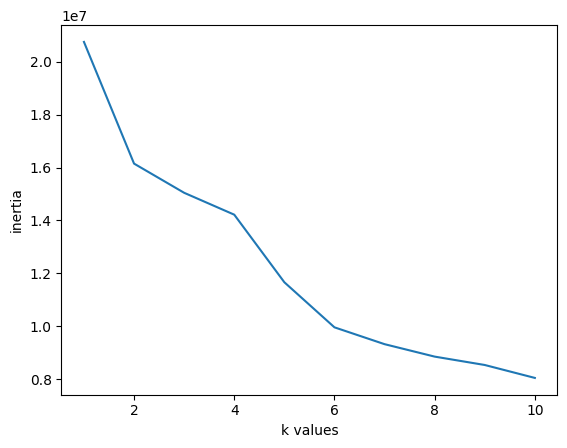

In [156]:
#ELBOW METHOD
plt.plot(range(1,11),wcss)
plt.xlabel("k values")
plt.ylabel('inertia')
plt.show()

In [157]:
#KMeans MODEL BUILDING WHERE K=6
kmeans=KMeans(n_clusters=6,init="k-means++",random_state=41)
clust=kmeans.fit(x_scaled)
labels=kmeans.labels_
df['cluster']=kmeans.labels_
df

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Month,Year,cluster
0,4.216,0.418,234.84,18.4,0.0,1.0,17.0,17,12,2006,0
1,5.360,0.436,233.63,23.0,0.0,1.0,16.0,17,12,2006,0
2,5.374,0.498,233.29,23.0,0.0,2.0,17.0,17,12,2006,0
3,5.388,0.502,233.74,23.0,0.0,1.0,17.0,17,12,2006,0
4,3.666,0.528,235.68,15.8,0.0,1.0,17.0,17,12,2006,0
...,...,...,...,...,...,...,...,...,...,...,...
2075254,0.946,0.000,240.43,4.0,0.0,0.0,0.0,20,11,2010,3
2075255,0.944,0.000,240.00,4.0,0.0,0.0,0.0,20,11,2010,3
2075256,0.938,0.000,239.82,3.8,0.0,0.0,0.0,21,11,2010,3
2075257,0.934,0.000,239.70,3.8,0.0,0.0,0.0,21,11,2010,3


In [158]:
df['cluster'].value_counts()

,count
cluster,
0,645561
1,508392
3,418350
2,399436
4,55842
5,47678


In [ ]:
#Performance Evaluation
from sklearn.metrics import silhouette_samples
print(silhouette_samples(x_scaled,labels))